Ejemplo_Interpolaciones 
comparacion con el archivo Script_interpolaciones de la toolbox simple_robotics-1.0.5

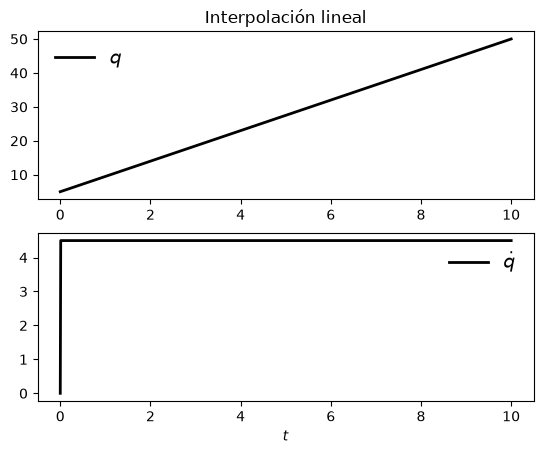

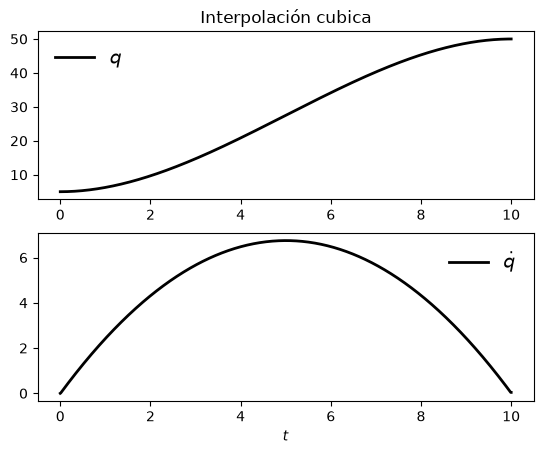

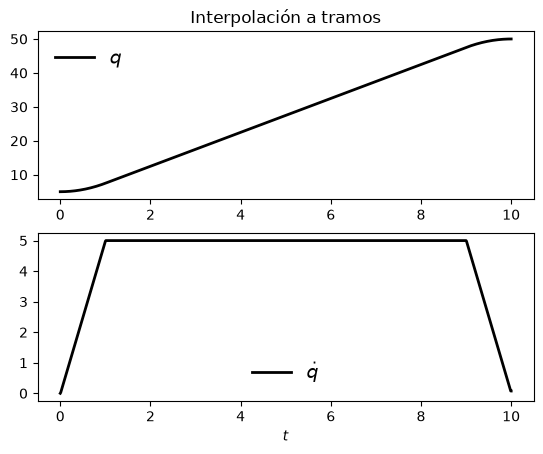

In [ ]:
#Interpolaciones usando funciones que regresan vectores
#Ejemplo de uso de las funciones de interpolacion usando como referencia el scrip Script_interpolacion de la toolbox simple_robotics-1.0.5

"""
Autor: Ing. Leonardo Andrey Gaspar Mejia
Autor Original del Script: Dr. César A. Chávez-Olivares 

"""

#Datos para la interpolacion 

import SimpleRobotics as rt 
import matplotlib.pyplot as plt
import numpy as np

q_i = 5
q_f = 50

qp_i = 0
qp_f = 0

t_i = 0
t_f = 10

T = t_f - t_i

ndatos = 1000

# En MATLAB: t=t_i: T/(ndatos-1): t_f; esta instrucion genera un vector de tiempos equidistantes, el equivalente en python es: 
# La sintaxis de linspace es np.linspace(inicio, final, cantidad_de_muestras)
t = np.linspace(t_i, t_f, ndatos) 

#Interpolacion Lineal 

q, qp = rt.interpolacion_lineal_vector(q_i, q_f, t)

fig1 = plt.figure(1)

ax1 = fig1.add_subplot(2, 1, 1)
ax1.plot(t, q, color="black", linewidth=2)
ax1.set_title("Interpolación lineal")
ax1.legend([r"$q$"], fontsize=14, loc="best", frameon=False)

ax2 = fig1.add_subplot(2, 1, 2)
ax2.plot(t, qp, color="black", linewidth=2)
ax2.set_xlabel(r"$t$")
ax2.legend([r"$\dot{q}$"], fontsize=14, loc="best", frameon=False)


# interpolacion cubica

q, qp = rt.interpolacion_cubica_vector(q_i, q_f, qp_i, qp_f, t)

fig2 = plt.figure(2)

ax1 = fig2.add_subplot(2, 1, 1)
ax1.plot(t, q, color="black", linewidth=2)
ax1.set_title("Interpolación cubica")
ax1.legend([r"$q$"], fontsize=14, loc="best", frameon=False)

ax2 = fig2.add_subplot(2, 1, 2)
ax2.plot(t, qp, color="black", linewidth=2)
ax2.set_xlabel(r"$t$")
ax2.legend([r"$\dot{q}$"], fontsize=14, loc="best", frameon=False)

# interpolacion por tramos

Vmax = 5 
Amax = 5

T = np.abs(q_f - q_i)/Vmax + Vmax/Amax

ndatos = 1000
t = np.linspace(0, T, ndatos) 

q, qp = rt.interpolacion_tramos_vector(q_i, q_f, Vmax, Amax, t)

fig3 = plt.figure(3)

ax1 = fig3.add_subplot(2, 1, 1)
ax1.plot(t, q, color="black", linewidth=2)
ax1.set_title("Interpolación a tramos")
ax1.legend([r"$q$"], fontsize=14, loc="best", frameon=False)

ax2 = fig3.add_subplot(2, 1, 2)
ax2.plot(t, qp, color="black", linewidth=2)
ax2.set_xlabel(r"$t$")
ax2.legend([r"$\dot{q}$"], fontsize=14, loc="best", frameon=False)


Comparacion don el archivo Script_trazo_interp_cubica

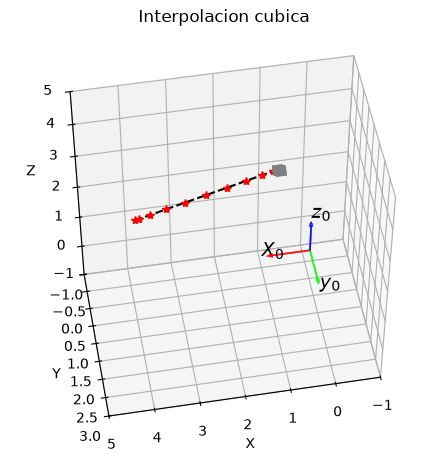

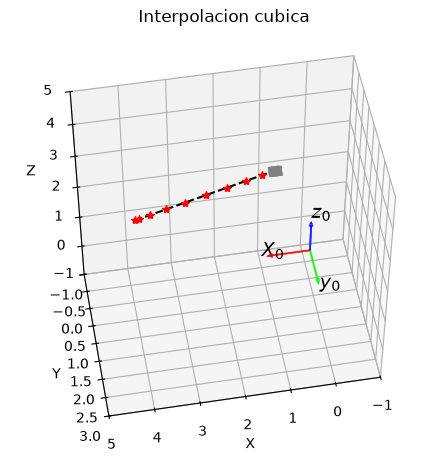

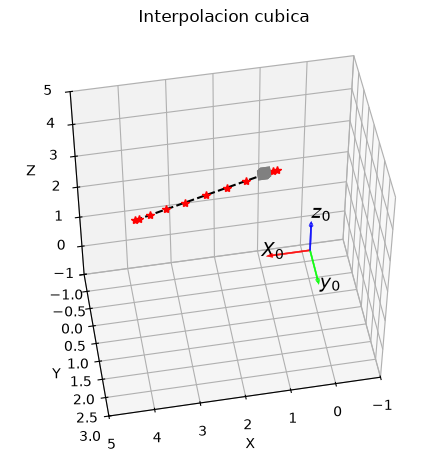

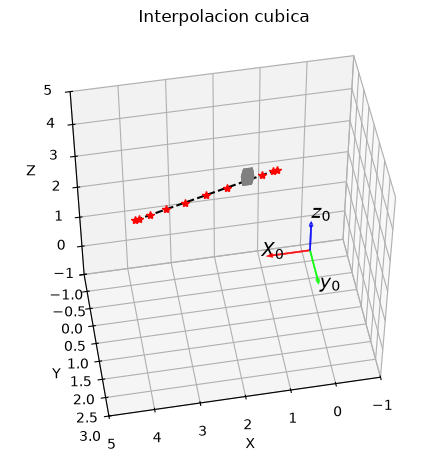

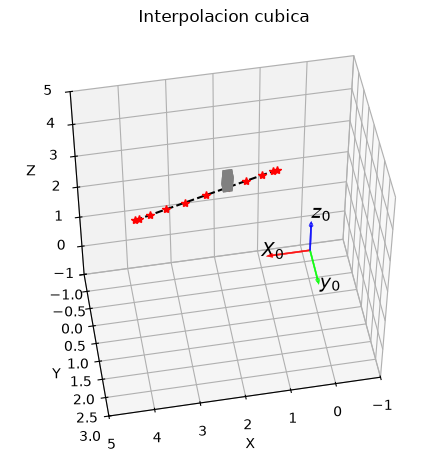

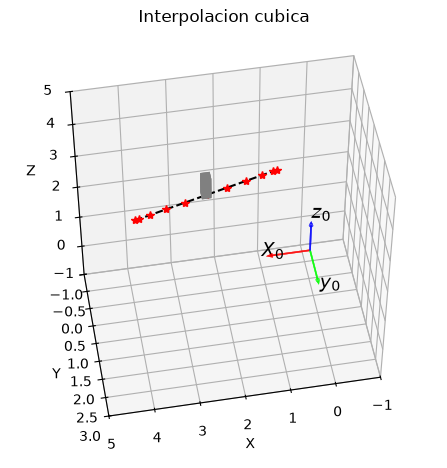

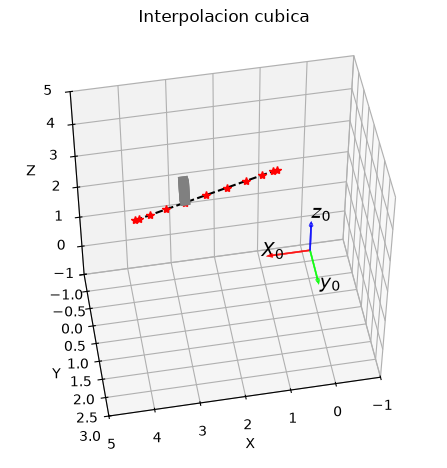

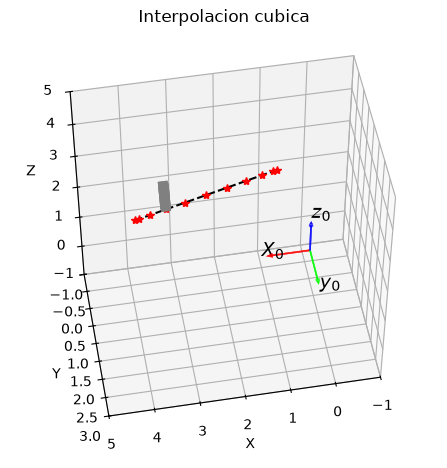

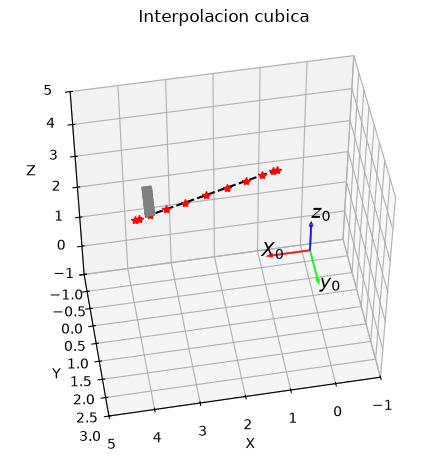

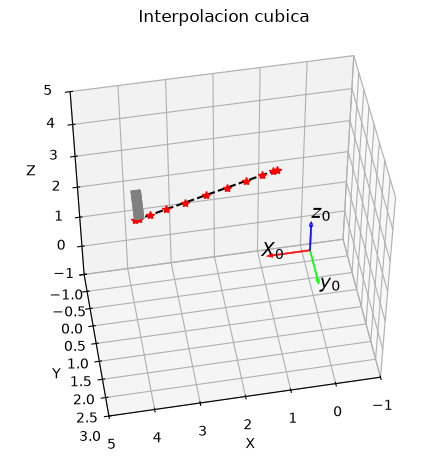

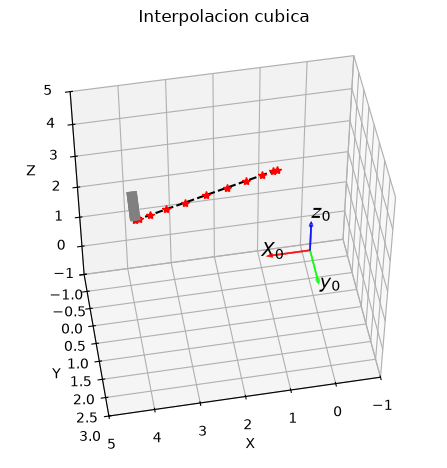

In [ ]:
# Ejercicio de interpolación para el cambio de postura de un objeto solido
"""
Script que permite simular el desplazamiento y cambio de orientacion de un objeto en el espacio.
Se usa interpolacion cúbica para la posición.
Se usa interpolacion cúbica para la orientación.

Autor: Ing. Leonardo Andrey Gaspar Mejia
Autor Original del Script: Dr. César A. Chávez-Olivares 
"""

import SimpleRobotics as rt 
from SimpleRobotics import rotx #Esto nos permite ahorranos rt. para usarlo de forma directa
import matplotlib.pyplot as plt
import numpy as np
from numpy import pi

Tk0 = rt.trans(1,1,4) @ rotx(-45*pi/180)  #Postura incial 
TkF = rt.trans(4,1,3) @ rotx(45*pi/180) #Postura Final 

H = rt.H_inv(Tk0) @ TkF #Utilizamos @ para una multiplicacion entre matrices ya que si usamos * numoy lo entiende como una multplicacion de escalares
d = H[0:3, 3]

Lambda, theta_ = rt.Eje_theta(H)

#Interpolacion de datos 

t = np.linspace(0, 1, 11) 

x, xp = rt.interpolacion_cubica_vector(0, d[0], 0, 0, t)
y, yp = rt.interpolacion_cubica_vector(0, d[1], 0, 0, t)
z, zp = rt.interpolacion_cubica_vector(0, d[2], 0, 0, t)
theta, thetap = rt.interpolacion_cubica_vector(0, theta_, 0, 0, t)

# Trasladar los datos interpolados

datos = np.vstack((
    x, 
    y,
    z,
    np.ones_like(x)
))
ndatos = Tk0 @ datos
XX = ndatos[0, :]
YY = ndatos[1, :]
ZZ = ndatos[2, :]

# Dibujar sistemas 

for ii in range(len(t)):

    #np.array permite crear el vector columna equivalente en MATLAB en di = [x(ii); y(ii); z(ii)];
    di = np.array([ [x[ii]], [y[ii]], [z[ii]]]) 

    if theta_ > 0:
        Ri = rt.Rot_eje(Lambda, theta[ii])
    else:
        Ri = np.eye(3)

    Hi =  np.block([[Ri, di], [np.zeros((1, 3)), np.ones((1, 1))]]) # np.block nos permite crear una matriz apartir de bloques muy parecido a como lo hace MATLAB

    Tki = Tk0 @ Hi

    fig, ax = rt.Dibujar_intermedio(Tk0, TkF, Tki, 1)

    ax.plot(XX, YY, ZZ, "*r")
    ax.set_title("Interpolacion cubica")

    plt.draw()
    plt.pause(.1)








C:\Users\leoag\OneDrive\Documentos\SimpleRobotics_v1.0.5.1\src\SimpleRobotics\__init__.py
False
